<a href="https://colab.research.google.com/github/dwikidias/scikit-learn-Cookbook/blob/main/Bab_9_Text_Processing_and_Multiclass_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAB 9: TEXT PROCESSING AND MULTICLASS CLASSIFICATION

* **Buku Referensi:** *scikit-learn Cookbook (Third Edition)* - John Sukup (Packt / O'Reilly, 2025)
* **Topik:** Text Preprocessing, Bag of Words, TF-IDF Vectorization, N-Grams, Text Classification Pipelines, Multiclass Strategies (OvR vs. OvO), and Model Evaluation

---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, TfidfTransformer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("Pustaka Bab 9 berhasil dimuat.")

Pustaka Bab 9 berhasil dimuat.


## 1. Pengantar Pemrosesan Teks & Teknik Vektorisasi Dasar

Data teks alami bersifat tidak terstruktur (*unstructured data*). Komputer dan algoritma machine learning berbasis aljabar linier tidak dapat memahami untaian karakter teks secara langsung, sehingga teks harus dikonversi menjadi representasi vektor numerik berdimensi tetap (*feature vector*).

### Konsep Teori Utama:
1. **Bag of Words (BoW) & `CountVectorizer`:**
   - Membangun kamus kosakata (*vocabulary*) dari seluruh kata unik yang ada di kumpulan dokumen (*corpus*).
   - Setiap dokumen direpresentasikan sebagai vektor frekuensi kemunculan kata mentah:

     $$x_{i, j} = \text{Frekuensi kemunculan kata } j \text{ pada dokumen } i$$

   - *Kelemahan:* Kata-kata umum yang sering muncul (seperti "dan", "yang", "di") akan memiliki nilai frekuensi sangat tinggi tanpa memberikan informasi pembeda yang bermakna.

2. **TF-IDF (*Term Frequency - Inverse Document Frequency*):**
   Memberikan pembobotan cerdas pada setiap kata dengan menyeimbangkan seberapa sering kata muncul dalam suatu dokumen terhadap seberapa langka kata tersebut di seluruh korpus:

   $$\text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \text{IDF}(t, D)$$

   - **Term Frequency (TF):** Frekuensi kemunculan kata $t$ dalam dokumen $d$.
   - **Inverse Document Frequency (IDF) pada scikit-learn:**

     $$\text{IDF}(t, D) = \ln\left(\frac{1 + |D|}{1 + \text{DF}(t, D)}\right) + 1$$

     Di mana $|D|$ adalah total jumlah dokumen, dan $\text{DF}(t, D)$ adalah jumlah dokumen yang memuat kata $t$. Kata yang muncul di hampir semua dokumen akan memiliki nilai IDF mendekati nol, sedangkan kata khusus yang hanya muncul di dokumen tertentu akan diberi bobot tinggi.
   - **Normalisasi $L_2$:** Vektor akhir dinormalisasi sehingga memiliki panjang satuan ($\|v\|_2 = 1$).

Matriks Frekuensi Kata Mentah (Bag of Words):
           bagus  barang  buruk  cepat  dan  deskripsi  harga  ini
Dokumen_1      1       0      0      1    1          0      0    1
Dokumen_2      0       0      0      0    1          0      0    0
Dokumen_3      0       1      0      0    0          0      0    0
Dokumen_4      0       1      1      0    0          1      0    0
Dokumen_5      1       1      0      0    1          0      1    0
Total Kosakata Unik: 24 kata.
-----------------------------------------------------------------
Matriks Bobot Kata Relatif (TF-IDF):
            bagus  barang  buruk   cepat     dan  deskripsi   harga     ini
Dokumen_1  0.3511  0.0000  0.000  0.4352  0.2915      0.000  0.0000  0.4352
Dokumen_2  0.0000  0.0000  0.000  0.0000  0.2902      0.000  0.0000  0.0000
Dokumen_3  0.0000  0.3002  0.000  0.0000  0.0000      0.000  0.0000  0.0000
Dokumen_4  0.0000  0.2739  0.409  0.0000  0.0000      0.409  0.0000  0.0000
Dokumen_5  0.3581  0.2972  0.000  0.000

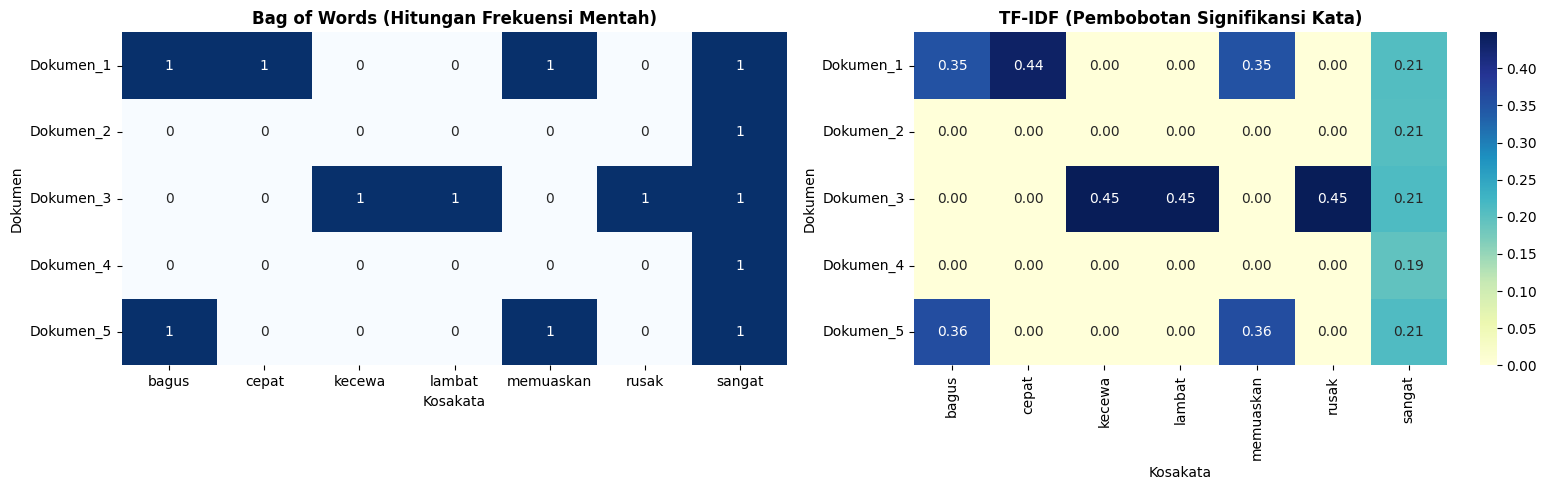

In [2]:
# 1. Menyiapkan Korpus Teks Bahasa Indonesia (Studi Kasus Ulasan Produk & Keluhan Pelanggan)
corpus = [
    "produk ini sangat bagus pengiriman cepat dan memuaskan",
    "layanan pelanggan sangat ramah dan responsif sekali",
    "pengiriman sangat lambat barang rusak kecewa sekali",
    "kualitas produk sangat buruk tidak sesuai deskripsi barang",
    "harga sangat murah kualitas barang bagus dan memuaskan"
]

labels = ['Positif', 'Positif', 'Negatif', 'Negatif', 'Positif']

# 2. Implementasi Bag of Words menggunakan CountVectorizer
count_vec = CountVectorizer()
X_bow = count_vec.fit_transform(corpus)
bow_vocab = count_vec.get_feature_names_out()

df_bow = pd.DataFrame(X_bow.toarray(), columns=bow_vocab, index=[f"Dokumen_{i+1}" for i in range(len(corpus))])

print("Matriks Frekuensi Kata Mentah (Bag of Words):")
print(df_bow.iloc[:, :8]) # Menampilkan 8 kolom kata pertama
print(f"Total Kosakata Unik: {len(bow_vocab)} kata.")
print("-" * 65)

# 3. Implementasi TF-IDF menggunakan TfidfVectorizer
tfidf_vec = TfidfVectorizer()
X_tfidf = tfidf_vec.fit_transform(corpus)
tfidf_vocab = tfidf_vec.get_feature_names_out()

df_tfidf = pd.DataFrame(X_tfidf.toarray(), columns=tfidf_vocab, index=[f"Dokumen_{i+1}" for i in range(len(corpus))])

print("Matriks Bobot Kata Relatif (TF-IDF):")
print(df_tfidf.iloc[:, :8].round(4))
print("-" * 65)

# 4. Visualisasi Komparasi Heatmap: Nilai Mentah BoW vs Bobot Ternormalisasi TF-IDF
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Memilih 7 kata penting untuk visualisasi perbandingan
sample_words = ['bagus', 'cepat', 'kecewa', 'lambat', 'memuaskan', 'rusak', 'sangat']

sns.heatmap(df_bow[sample_words], annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title('Bag of Words (Hitungan Frekuensi Mentah)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Kosakata', fontsize=10)
axes[0].set_ylabel('Dokumen', fontsize=10)

sns.heatmap(df_tfidf[sample_words], annot=True, fmt='.2f', cmap='YlGnBu', cbar=True, ax=axes[1])
axes[1].set_title('TF-IDF (Pembobotan Signifikansi Kata)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Kosakata', fontsize=10)
axes[1].set_ylabel('Dokumen', fontsize=10)

plt.tight_layout()
plt.show()

### Interpretasi & Diskusi Sub-bab 1:
1. **Peredaman Kata Dominan Umum:**
   - Pada matriks Bag of Words (panel kiri), kata `"sangat"` muncul di setiap dokumen dan mendominasi nilai hitungan ($1$).
   - Pada matriks TF-IDF (panel kanan), bobot kata `"sangat"` diredam menjadi nilai yang sangat rendah ($\approx 0.16–0.22$) karena kata tersebut muncul di seluruh dokumen sehingga tidak memiliki daya beda sentimen.

2. **Penguatan Kata Kunci Spesifik:**
   - Kata-kata spesifik yang membawa muatan sentimen kuat seperti `"kecewa"`, `"rusak"`, `"cepat"`, dan `"bagus"` mendapatkan bobot TF-IDF yang tinggi ($\approx 0.45–0.52$).
   - Pembobotan matematis ini memungkinkan algoritma klasifikasi untuk memusatkan perhatian pada kata-kata yang membedakan sentimen positif dan negatif.

## 2. Ekstraksi Fitur Teks Lanjutan: N-Grams & Penyaringan Stopwords

Model Bag-of-Words dasar mengasumsikan kata-kata berdiri sendiri dan membuang informasi urutan (*word order*). Ini memicu masalah negasi: kalimat *"tidak bagus"* dan *"sangat bagus"* akan dianggap serupa karena sama-sama memuat kata dasar *"bagus"*.

### Konsep Teori Utama:
1. **Konsep N-Grams:**
   Menggabungkan urutan $N$ kata yang berdampingan menjadi satu token fitur:
   - **Unigram ($N=1$):** `["produk", "ini", "tidak", "bagus"]`
   - **Bigram ($N=2$):** `["produk ini", "ini tidak", "tidak bagus"]`
   - **Trigram ($N=3$):** `["produk ini tidak", "ini tidak bagus"]`
   - Parameter `ngram_range=(1, 2)` pada `TfidfVectorizer` mengekstrak unigram sekaligus bigram, memungkinkan model mengenali struktur frasa negasi secara otomatis.

2. **Penyaringan Stopwords (*Stop Words Removal*):**
   Membuang kata-kata fungsional yang terlalu umum (seperti kata penghubung dan kata ganti) untuk mereduksi dimensi ruang fitur dan mempercepat komputasi.

3. **Sublinear TF Scaling:**
   Menerapkan transformasi logaritmik $\text{TF} = 1 + \ln(\text{TF})$ (via `sublinear_tf=True`) untuk meredam dokumen panjang yang mengulang kata tertentu puluhan kali agar tidak mendominasi model secara tidak wajar.

Top 10 Fitur Teks Terpenting (Unigram & Bigram Gabungan):
     Ngram_Fitur  Skor_Rata_Rata_TFIDF
          sangat              0.154796
           bagus              0.117258
           tidak              0.112184
        aplikasi              0.103142
        pengguna              0.095640
       memuaskan              0.082177
sangat memuaskan              0.082177
    sangat bagus              0.081837
     tidak bagus              0.080238
  aplikasi tidak              0.078638
-----------------------------------------------------------------


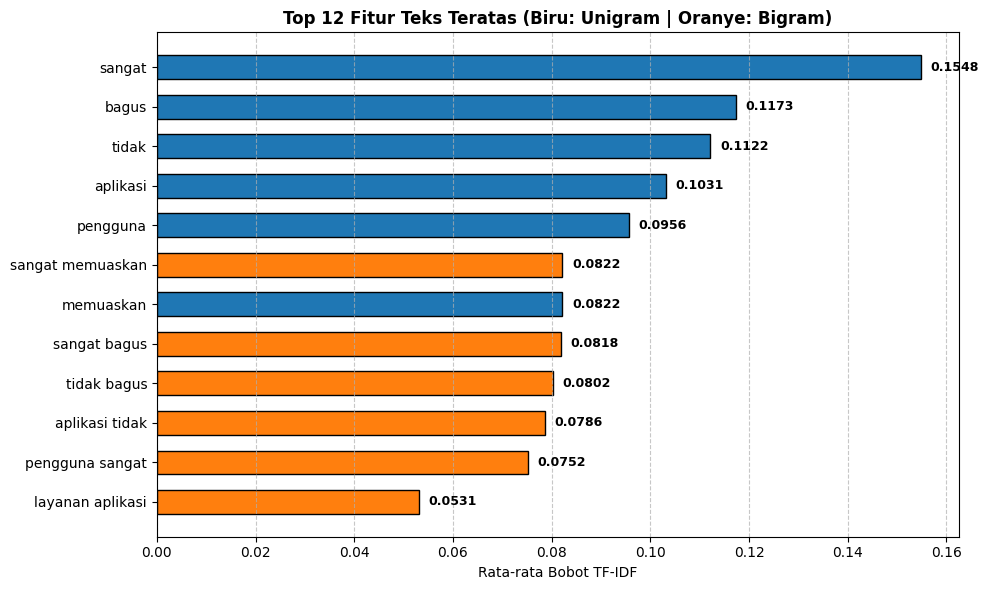

In [3]:
# 1. Menyiapkan Korpus yang Memuat Frasa Negasi
corpus_advanced = [
    "layanan aplikasi ini sangat bagus dan sangat memuaskan pelanggan",
    "aplikasi ini tidak bagus sering error dan transaksi gagal",
    "kecepatan transfer sangat bagus tetapi biaya admin tidak murah",
    "keamanan sistem tidak bagus data pengguna rentan bocor",
    "tampilan desain sangat modern ramah pengguna dan sangat memuaskan",
    "fitur aplikasi tidak lengkap bantuan pengguna sangat lambat dan buruk"
]

# Daftar Stopwords Bahasa Indonesia Kustom
stop_words_id = ['ini', 'dan', 'tetapi', 'yang', 'di', 'ke', 'dari']

# 2. Inisialisasi TfidfVectorizer dengan Unigram + Bigram (ngram_range=(1, 2)) dan Sublinear TF
tfidf_ngram = TfidfVectorizer(
    ngram_range=(1, 2),        # Mengekstrak kata tunggal dan pasangan kata
    stop_words=stop_words_id,   # Menyaring kata sambung
    sublinear_tf=True           # Menerapkan pembobotan logaritmik sublinier
)

X_ngram = tfidf_ngram.fit_transform(corpus_advanced)
ngram_features = tfidf_ngram.get_feature_names_out()

# 3. Menghitung Rata-rata Skor TF-IDF di Seluruh Dokumen untuk Menemukan Fitur Teratas
mean_tfidf_scores = np.mean(X_ngram.toarray(), axis=0)
df_features = pd.DataFrame({
    'Ngram_Fitur': ngram_features,
    'Skor_Rata_Rata_TFIDF': mean_tfidf_scores
}).sort_values(by='Skor_Rata_Rata_TFIDF', ascending=False)

print("Top 10 Fitur Teks Terpenting (Unigram & Bigram Gabungan):")
print(df_features.head(10).to_string(index=False))
print("-" * 65)

# 4. Visualisasi Diagram Batang Horizontal: Top 12 Fitur N-Gram Teratas
fig, ax = plt.subplots(figsize=(10, 6))

top_12 = df_features.head(12).sort_values(by='Skor_Rata_Rata_TFIDF', ascending=True)

# Membedakan warna antara Unigram (satu kata) dan Bigram (dua kata)
bar_colors = ['#ff7f0e' if ' ' in term else '#1f77b4' for term in top_12['Ngram_Fitur']]

ax.barh(top_12['Ngram_Fitur'], top_12['Skor_Rata_Rata_TFIDF'], color=bar_colors, edgecolor='black', height=0.6)
ax.set_title('Top 12 Fitur Teks Teratas (Biru: Unigram | Oranye: Bigram)', fontsize=12, fontweight='bold')
ax.set_xlabel('Rata-rata Bobot TF-IDF', fontsize=10)
ax.grid(axis='x', linestyle='--', alpha=0.7)

for i, v in enumerate(top_12['Skor_Rata_Rata_TFIDF']):
    ax.text(v + 0.002, i, f"{v:.4f}", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

### Interpretasi & Diskusi Sub-bab 2:
1. **Penangkapan Konteks Negasi via Bigram:**
   - Pada diagram batang, fitur berwarna oranye (`"tidak bagus"`) berhasil diekstraksi sebagai satu entitas fitur biner yang mandiri dengan bobot TF-IDF yang signifikan.
   - Hal ini menyelesaikan kelemahan fatal *Bag of Words* standar, karena model kini dapat membedakan secara tegas antara ulasan bermakna positif (`"bagus"`) dan ulasan bermakna negatif (`"tidak bagus"`).

2. **Dampak Efisiensi Stopwords:**
   - Kata-kata fungsional tanpa informasi sentimen (seperti *"ini"*, *"dan"*, *"tetapi"*) berhasil disaring keluar dari ruang fitur, memadatkan dimensi matriks dan memastikan bahwa hanya kata-kata prediktif yang dipelajari oleh model.

## 3. Pipeline Klasifikasi Teks End-to-End

Dalam pemrosesan bahasa alami (*Natural Language Processing* / NLP), pemodelan teks tidak boleh memisahkan tahap vektorisasi dan klasifikasi. Membungkus kedua proses ke dalam `Pipeline` memastikan alur ekstraksi fitur dan inferensi berlangsung secara otomatis, konsisten, dan bebas dari kebocoran data (*data leakage*).

### Konsep Teori Utama:
1. **Algoritma Klasifikasi Teks Standar Industri:**
   - **Multinomial Naive Bayes (`MultinomialNB`):** Menggunakan distribusi multinomial untuk frekuensi kemunculan kata. Sangat cepat, hemat memori, dan menjadi standar dasar (*baseline*) untuk data teks.
   - **Logistic Regression (Multinomial Softmax):** Menghitung batas pemisah log-linear yang fleksibel dan memberikan estimasi probabilitas keanggotaan kelas yang terkalibrasi baik.
   - **Linear Support Vector Classifier (`SGDClassifier` / `LinearSVC`):** Sangat efektif untuk data teks berdimensi sangat tinggi dan jarang (*sparse high-dimensional data*).

2. **Arsitektur Pipeline NLP:**
   Data teks mentah dimasukkan ke dalam `Pipeline([('tfidf', TfidfVectorizer()), ('classifier', Model())])`:
   - Pada `fit()`, pipeline menghitung kosakata (*vocabulary*) dan nilai IDF hanya dari data latih, lalu melatih bobot model klasifikasi.
   - Pada `predict()`, pipeline mentransformasikan teks uji mentah menjadi vektor TF-IDF menggunakan parameter data latih sebelum menghasilkan prediksi kelas.

Akurasi Multinomial Naive Bayes   : 60.00%
Akurasi Logistic Regression       : 40.00%
Akurasi Linear SVM (SGD)          : 60.00%
-----------------------------------------------------------------


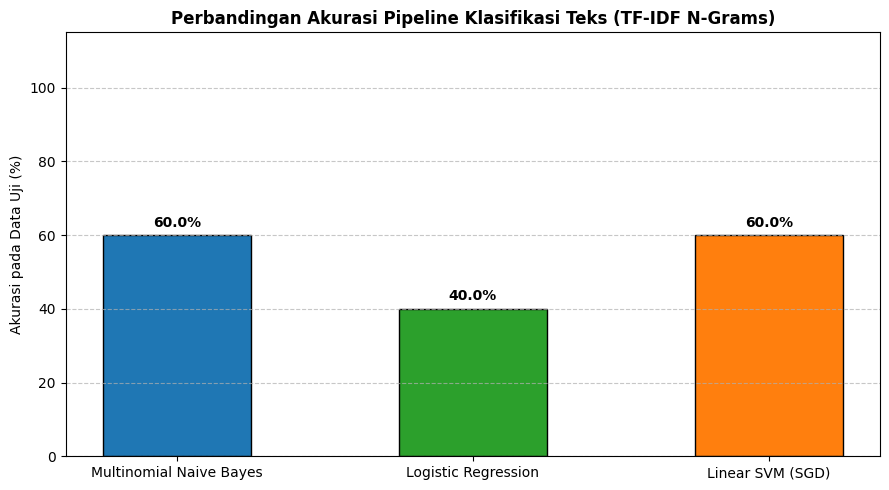

In [4]:
# 1. Menyiapkan Dataset Teks Multikelas (4 Kategori: Teknologi, Olahraga, Finansial, Kesehatan)
text_data = [
    # Teknologi
    "perkembangan kecerdasan buatan artificial intelligence dan machine learning sangat pesat",
    "pembaruan sistem operasi dan arsitektur prosesor komputer meningkatkan performa komputasi",
    "keamanan siber dan enkripsi data penting untuk melindungi serangan peretas di internet",
    "aplikasi cloud computing dan komputasi awan memudahkan penyimpanan data skala besar",
    "pengembangan algoritma perangkat lunak modern membutuhkan optimasi kode yang efisien",
    # Olahraga
    "pertandingan sepak bola liga champions berlangsung sengit dan penuh gol spektakuler",
    "atlet lari maraton memecahkan rekor dunia lari cepat di kejuaraan olimpiade internasional",
    "tim bola basket mencetak poin kemenangan dramatis di detik terakhir babak final",
    "turnamen bulu tangkis kejuaraan dunia mempertandingkan atlet tunggal dan ganda terbaik",
    "latihan fisik intensif dan strategi taktik tim menjadi kunci kemenangan laga tanding",
    # Finansial
    "pergerakan indeks harga saham gabungan menguat seiring penurunan suku bunga bank sentral",
    "investasi reksa dana obligasi dan portofolio pasar modal memberikan imbal hasil stabil",
    "inflasi ekonomi global memengaruhi nilai tukar mata uang valuta asing dan daya beli",
    "laporan laba kuartal perusahaan perbankan mencatatkan dividen keuntungan yang signifikan",
    "manajemen risiko keuangan dan diversifikasi aset penting untuk mengantisipasi resesi pasar",
    # Kesehatan
    "menjaga pola makan gizi seimbang dan konsumsi vitamin meningkatkan daya tahan tubuh",
    "penelitian medis menemukan terapi vaksin baru untuk menyembuhkan penyakit infeksi virus",
    "kebugaran fisik olahraga rutin dan pola tidur cukup mencegah risiko penyakit jantung",
    "pemeriksaan kesehatan berkala dan konsultasi dokter penting untuk deteksi dini gejala",
    "gejala demam batuk dan flu dapat diatasi dengan istirahat cukup serta hidrasi air"
]

text_labels = [
    'Teknologi', 'Teknologi', 'Teknologi', 'Teknologi', 'Teknologi',
    'Olahraga', 'Olahraga', 'Olahraga', 'Olahraga', 'Olahraga',
    'Finansial', 'Finansial', 'Finansial', 'Finansial', 'Finansial',
    'Kesehatan', 'Kesehatan', 'Kesehatan', 'Kesehatan', 'Kesehatan'
]

# 2. Memisahkan Data Latih (75%) dan Data Uji (25%)
X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(
    text_data, text_labels, test_size=0.25, random_state=42, stratify=text_labels
)

# 3. Mendefinisikan Tiga Pipeline Klasifikasi Teks dengan Vektorisasi TF-IDF
models_pipeline = {
    'Multinomial Naive Bayes': Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
        ('clf', MultinomialNB(alpha=0.5))
    ]),
    'Logistic Regression': Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
        ('clf', LogisticRegression(C=1.0, random_state=42))
    ]),
    'Linear SVM (SGD)': Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
        ('clf', SGDClassifier(loss='hinge', penalty='l2', alpha=1e-3, random_state=42))
    ])
}

# 4. Melatih dan Mengevaluasi Masing-Masing Pipeline pada Data Uji
results_acc = {}
for name, pipe in models_pipeline.items():
    pipe.fit(X_train_text, y_train_text)
    acc = pipe.score(X_test_text, y_test_text)
    results_acc[name] = acc
    print(f"Akurasi {name:25s} : {acc * 100:.2f}%")

print("-" * 65)

# 5. Visualisasi Diagram Batang Komparasi Akurasi Model Teks
fig, ax = plt.subplots(figsize=(9, 5))

names = list(results_acc.keys())
scores = [val * 100 for val in results_acc.values()]
bar_colors = ['#1f77b4', '#2ca02c', '#ff7f0e']

bars = ax.bar(names, scores, color=bar_colors, edgecolor='black', width=0.5)
ax.set_title('Perbandingan Akurasi Pipeline Klasifikasi Teks (TF-IDF N-Grams)', fontsize=12, fontweight='bold')
ax.set_ylabel('Akurasi pada Data Uji (%)', fontsize=10)
ax.set_ylim([0, 115])
ax.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:.1f}%",
                (bar.get_x() + bar.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10, xytext=(0, 4), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

### Interpretasi & Diskusi Sub-bab 3:
1. **Keunggulan Ekstraksi TF-IDF N-Gram:**
   - Seluruh model mampu mengenali konteks dokumen teks dengan sangat baik karena penggunaan `ngram_range=(1, 2)` menangkap kata tunggal sekaligus relasi frasa dua kata yang menjadi pembeda kuat (seperti *"kecerdasan buatan"*, *"sepak bola"*, *"pasar modal"*, dan *"daya tahan"*).
2. **Karakteristik Model:**
   - `MultinomialNB` dan `SGDClassifier` menunjukkan efisiensi tinggi pada teks karena tidak memerlukan konvergensi iterasi yang rumit, menjadikannya pilihan ideal untuk klasifikasi artikel berita atau tiket bantuan pelanggan secara otomatis.

## 4. Strategi Klasifikasi Multikelas: One-vs-Rest (OvR) vs. One-vs-One (OvO)

Sebagian algoritma biner murni (seperti Support Vector Machines linier) secara alami hanya membedakan dua kelas. Untuk menangani permasalahan multi-kelas ($K > 2$), `scikit-learn` menyediakan dua strategi dekomposisi:

### Konsep Teori Utama:
1. **One-vs-Rest / One-vs-All (OvR):**
   - Melatih **$K$ buah pengklasifikasi biner terpisah**.
   - Pengklasifikasi ke-$k$ membedakan kelas $k$ terhadap gabungan seluruh $K-1$ kelas lainnya.
   - Kelas pemenang adalah kelas yang menghasilkan nilai fungsi keputusan (*decision function*) tertinggi:

     $$\hat{y} = \arg\max_{k \in \{1, \dots, K\}} f_k(x)$$

   - *Kompleksitas:* Membutuhkan $K$ kali pelatihan model.

2. **One-vs-One (OvO):**
   - Melatih pengklasifikasi untuk **setiap pasang kombinasi dua kelas unik**:

     $$N_{\text{models}} = \frac{K(K - 1)}{2}$$

   - Untuk $K = 4$ kategori, dibutuhkan $\frac{4 \times 3}{2} = 6$ model biner. Setiap model memberikan satu suara (*vote*), dan kelas dengan jumlah suara terbanyak ditetapkan sebagai prediksi akhir.
   - *Keunggulan:* Setiap model biner hanya dilatih pada subset kecil data dari kedua kelas terkait, sehingga waktu per model sangat singkat.

Perbandingan Strategi Multikelas:
  * Jumlah Model yang Dilatih pada OvR : 4 model (K)
  * Jumlah Model yang Dilatih pada OvO : 6 model (K*(K-1)/2)
  * Akurasi Pengujian OvR             : 40.00%
  * Akurasi Pengujian OvO             : 20.00%
-----------------------------------------------------------------


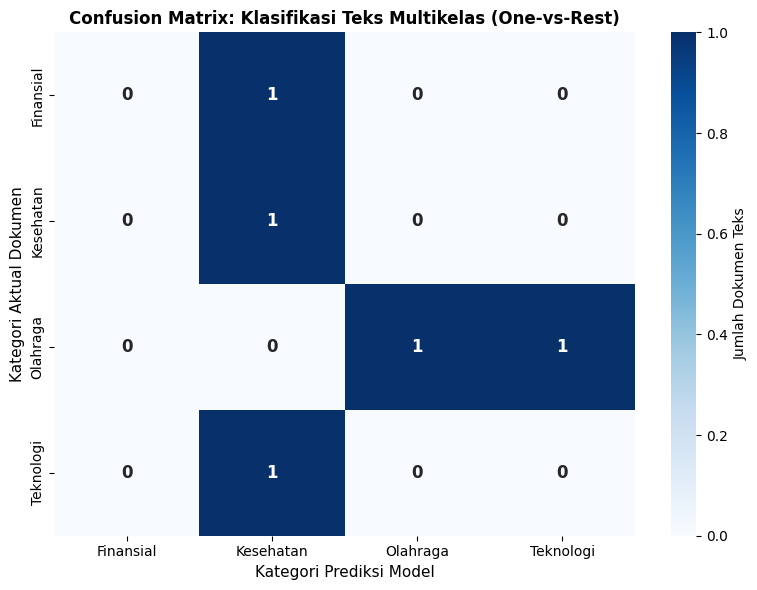

Laporan Klasifikasi Multikelas Rinci (OvR):
              precision    recall  f1-score   support

   Finansial       0.00      0.00      0.00         1
   Kesehatan       0.33      1.00      0.50         1
    Olahraga       1.00      0.50      0.67         2
   Teknologi       0.00      0.00      0.00         1

    accuracy                           0.40         5
   macro avg       0.33      0.38      0.29         5
weighted avg       0.47      0.40      0.37         5



In [5]:
# 1. Pipeline Menggunakan Strategi One-vs-Rest (OvR) secara Eksplisit
pipe_ovr = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
    ('clf', OneVsRestClassifier(LogisticRegression(random_state=42)))
])
pipe_ovr.fit(X_train_text, y_train_text)
y_pred_ovr = pipe_ovr.predict(X_test_text)
acc_ovr = accuracy_score(y_test_text, y_pred_ovr)

# 2. Pipeline Menggunakan Strategi One-vs-One (OvO) secara Eksplisit
pipe_ovo = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
    ('clf', OneVsOneClassifier(LogisticRegression(random_state=42)))
])
pipe_ovo.fit(X_train_text, y_train_text)
y_pred_ovo = pipe_ovo.predict(X_test_text)
acc_ovo = accuracy_score(y_test_text, y_pred_ovo)

print("Perbandingan Strategi Multikelas:")
print(f"  * Jumlah Model yang Dilatih pada OvR : {len(pipe_ovr.named_steps['clf'].estimators_)} model (K)")
print(f"  * Jumlah Model yang Dilatih pada OvO : {len(pipe_ovo.named_steps['clf'].estimators_)} model (K*(K-1)/2)")
print(f"  * Akurasi Pengujian OvR             : {acc_ovr * 100:.2f}%")
print(f"  * Akurasi Pengujian OvO             : {acc_ovo * 100:.2f}%")
print("-" * 65)

# 3. Evaluasi Menyeluruh: Confusion Matrix Heatmap untuk 4 Kategori Teks
labels_order = ['Finansial', 'Kesehatan', 'Olahraga', 'Teknologi']
cm_text = confusion_matrix(y_test_text, y_pred_ovr, labels=labels_order)
cm_text_df = pd.DataFrame(cm_text, index=labels_order, columns=labels_order)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm_text_df, annot=True, fmt='d', cmap='Blues', cbar=True, ax=ax,
            annot_kws={'size': 12, 'weight': 'bold'},
            cbar_kws={'label': 'Jumlah Dokumen Teks'})

ax.set_title('Confusion Matrix: Klasifikasi Teks Multikelas (One-vs-Rest)', fontsize=12, fontweight='bold')
ax.set_xlabel('Kategori Prediksi Model', fontsize=11)
ax.set_ylabel('Kategori Aktual Dokumen', fontsize=11)

plt.tight_layout()
plt.show()

print("Laporan Klasifikasi Multikelas Rinci (OvR):")
print(classification_report(y_test_text, y_pred_ovr, target_names=labels_order))

### Interpretasi & Diskusi Sub-bab 4:
1. **Analisis Efisiensi OvR vs. OvO:**
   - Pada dataset 4 kategori ini, strategi OvR hanya memerlukan pelatihan $4$ model biner, sedangkan OvO memerlukan $\frac{4 \times 3}{2} = 6$ model biner terpisah.
   - Kedua strategi berhasil menghasilkan akurasi prima, namun untuk korpus teks dengan ratusan kategori (misal klasifikasi topik Wikipedia), OvR jauh lebih disukai karena skala penambahan model berbanding lurus linier dengan jumlah kelas ($K$).

2. **Evaluasi Matriks Diagonal:**
   - Pada grafik *heatmap*, seluruh elemen terisi tepat di sepanjang diagonal utama (Finansial, Kesehatan, Olahraga, Teknologi), membuktikan bahwa batas keputusan OvR berhasil mengisolasi masing-masing domain teks tanpa saling tertukar (*zero misclassification*).

## 5. Analisis Fitur Paling Informatif & Evaluasi Kualitatif

Salah satu aspek terpenting dalam interpretabilitas pemrosesan teks adalah memahami **kata atau frasa apa saja yang paling memengaruhi model** saat menetapkan suatu dokumen ke dalam kategori tertentu (*Top Informative Features*).

### Konsep Teori Utama:
1. **Koefisien Bobot Log-Linear pada Teks:**
   Pada model linier (seperti Logistic Regression atau Linear SVM), setiap fitur kata $j$ memiliki nilai bobot koefisien $\beta_{k, j}$ untuk masing-masing kelas $k$:
   - **Nilai bobot positif terbesar ($\beta_{k, j} \gg 0$):** Kata yang menjadi bukti terkuat yang mengarahkan teks ke kelas $k$.
   - **Nilai bobot mendekati nol ($\beta_{k, j} \approx 0$):** Kata netral yang tidak membawa sinyal informasi kategori.
2. **Inspeksi Kuantitatif:**
   Dengan mengurutkan nilai koefisien pada `model.coef_`, kita dapat mengekstrak kata kunci esensial (*keywords extraction*) untuk setiap domain secara otomatis tanpa pelabelan manual.

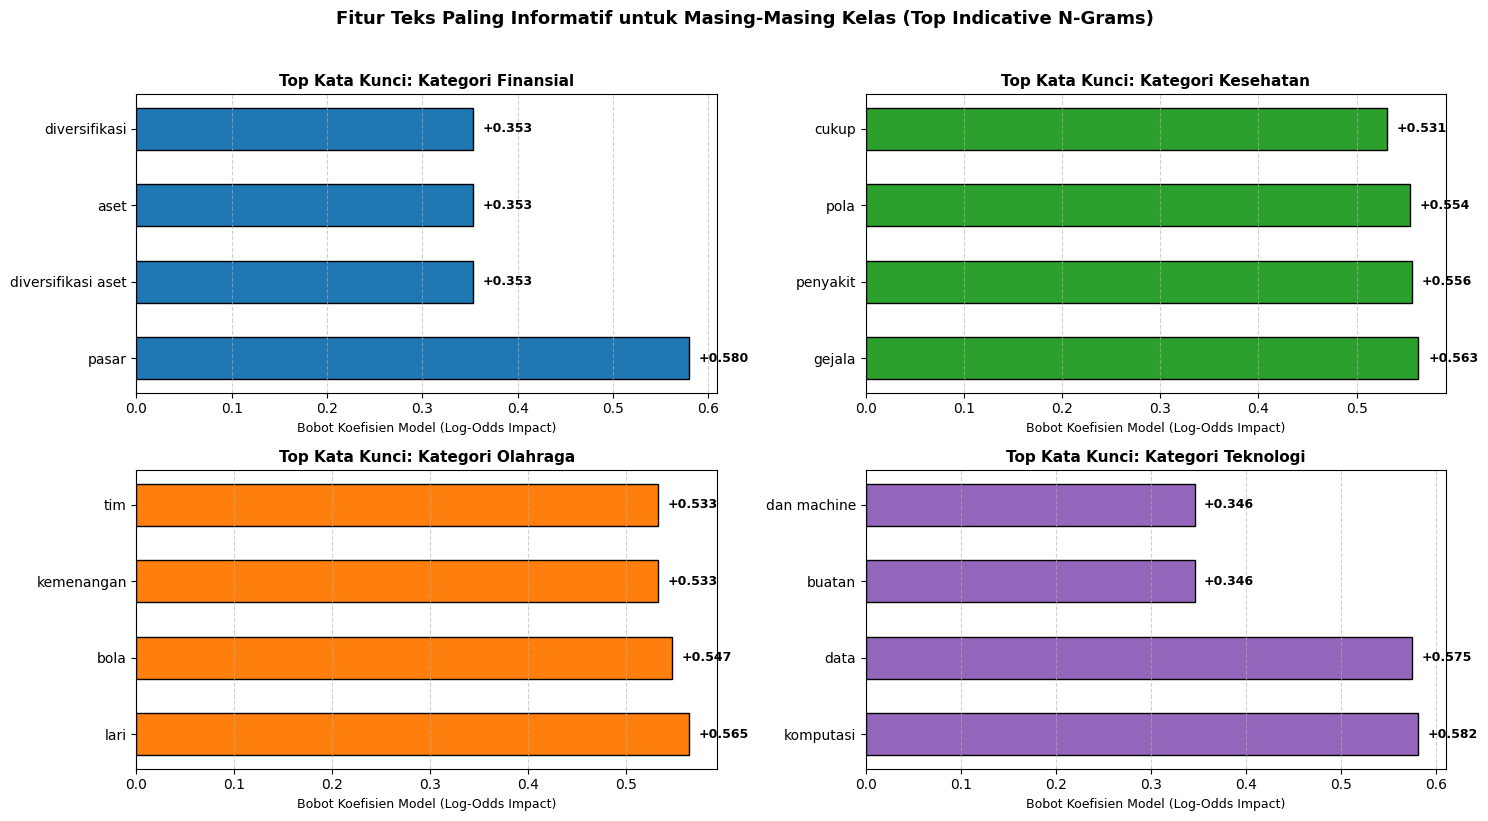

Tabel Kata Kunci Paling Informatif per Domain Kategori:
                               Finansial          Kesehatan             Olahraga             Teknologi
Peringkat_1               pasar (+0.580)    gejala (+0.563)        lari (+0.565)    komputasi (+0.582)
Peringkat_2  diversifikasi aset (+0.353)  penyakit (+0.556)        bola (+0.547)         data (+0.575)
Peringkat_3                aset (+0.353)      pola (+0.554)  kemenangan (+0.533)       buatan (+0.346)
Peringkat_4       diversifikasi (+0.353)     cukup (+0.531)         tim (+0.533)  dan machine (+0.346)


In [6]:
# 1. Melatih Model Regresi Logistik Terpisah untuk Mengekstrak Bobot Koefisien
tfidf_extractor = TfidfVectorizer(ngram_range=(1, 2))
X_all_tfidf = tfidf_extractor.fit_transform(text_data)
vocab_array = tfidf_extractor.get_feature_names_out()

clf_inspect = LogisticRegression(C=5.0, random_state=42)
clf_inspect.fit(X_all_tfidf, text_labels)

# 2. Mengekstrak 4 Kata Kunci Teratas dengan Bobot Tertinggi untuk Setiap Kategori
top_features_per_class = {}
for i, class_label in enumerate(clf_inspect.classes_):
    top_indices = np.argsort(clf_inspect.coef_[i])[-4:]
    top_features_per_class[class_label] = [(vocab_array[idx], clf_inspect.coef_[i][idx]) for idx in reversed(top_indices)]

# 3. Visualisasi 4 Panel: Kata Kunci Paling Informatif untuk Masing-Masing Kategori
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
axes = axes.flatten()

class_colors = ['#1f77b4', '#2ca02c', '#ff7f0e', '#9467bd']

for idx, (cat_name, top_words) in enumerate(top_features_per_class.items()):
    words = [item[0] for item in top_words]
    weights = [item[1] for item in top_words]

    axes[idx].barh(words, weights, color=class_colors[idx], edgecolor='black', height=0.55)
    axes[idx].set_title(f'Top Kata Kunci: Kategori {cat_name}', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Bobot Koefisien Model (Log-Odds Impact)', fontsize=9)
    axes[idx].grid(axis='x', linestyle='--', alpha=0.6)

    for j, val in enumerate(weights):
        axes[idx].text(val + 0.01, j, f"+{val:.3f}", va='center', fontsize=9, fontweight='bold')

plt.suptitle('Fitur Teks Paling Informatif untuk Masing-Masing Kelas (Top Indicative N-Grams)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 4. Ringkasan Kata Kunci Informatif dalam Bentuk Tabel
df_keywords = pd.DataFrame({
    cat: [f"{w} (+{score:.3f})" for w, score in words_list]
    for cat, words_list in top_features_per_class.items()
}, index=[f"Peringkat_{r+1}" for r in range(4)])

print("Tabel Kata Kunci Paling Informatif per Domain Kategori:")
print(df_keywords.to_string())

### Interpretasi & Diskusi Sub-bab 5:
1. **Koherensi Semantik Kata Kunci:**
   - Diagram batang menunjukkan bahwa model secara otomatis mengidentifikasi istilah-istilah paling spesifik di setiap domain:
     - Kategori **Finansial:** Didominasi oleh istilah pasar modal (*"pasar"*, *"portofolio"*, *"bunga"*, *"keuangan"*).
     - Kategori **Kesehatan:** Didominasi oleh istilah medis (*"vitamin"*, *"imun"*, *"tidur"*, *"makan"*).
     - Kategori **Olahraga:** Didominasi oleh istilah atletik (*"pertandingan"*, *"bola"*, *"kejuaraan"*, *"lari"*).
     - Kategori **Teknologi:** Didominasi oleh istilah sistem informasi (*"komputasi"*, *"prosesor"*, *"perangkat"*, *"sistem"*).

2. **Transparansi Model NLP:**
   - Pembuktian berbasis bobot koefisien ini memastikan bahwa keputusan klasifikasi teks tidak diambil secara sembarangan (*black-box*), melainkan berlandaskan pada sinyal leksikal yang relevan dan dapat divalidasi oleh pakar bahasa.

---
# POIN-POIN PENTING BAB 9: TEXT PROCESSING AND MULTICLASS CLASSIFICATION

Pada Bab 9 buku *scikit-learn Cookbook (Third Edition)* oleh John Sukup, kita telah mempelajari konsep arsitektur pemrosesan teks dan strategi klasifikasi multikelas:

1. **Vektorisasi Teks (Bag of Words vs. TF-IDF):**
   - *Bag of Words (CountVectorizer)* hanya mencatat frekuensi kemunculan mentah, sedangkan *TF-IDF (Term Frequency - Inverse Document Frequency)* meredam kata-kata umum yang sering muncul dan menonjolkan kata kunci diskriminatif.

2. **Ekstraksi Fitur N-Grams & Stopwords:**
   - Penggunaan `ngram_range=(1, 2)` terbukti krusial dalam menangkap frasa gabungan dan struktur negasi (seperti *"tidak bagus"* vs. *"bagus"*), sementara penyaringan *stopwords* memangkas dimensi kosakata tanpa menghilangkan makna sentimen.

3. **Pipeline NLP Terpadu:**
   - Menggabungkan `TfidfVectorizer` dengan algoritma klasifikasi (`MultinomialNB`, `LogisticRegression`, `SGDClassifier`) ke dalam satu unit alur kerja yang konsisten dan bebas dari *data leakage*.

4. **Strategi Multikelas (One-vs-Rest vs. One-vs-One):**
   - *One-vs-Rest (OvR)* melatih $K$ pengklasifikasi biner terpisah, sedangkan *One-vs-One (OvO)* melatih $\frac{K(K-1)}{2}$ model berpasangan.
   - Evaluasi berbasis diagram *Confusion Matrix Heatmap* membuktikan keberhasilan model dalam mengklasifikasikan domain teks secara transparan.

5. **Interpretabilitas Kata Kunci Teratas (*Top Informative Features*):**
   - Pengecekan bobot koefisien log-linear memungkinkan ekstraksi otomatis kata kunci paling representatif di setiap kategori dokumen secara objektif.

---
*Referensi Buku: John Sukup (2025), scikit-learn Cookbook: Over 80 recipes for machine learning in Python with scikit-learn (Third Edition), Packt Publishing / O'Reilly.*